# Methanol synthesis loop: PFR surrogate pipeline

One run, top to bottom, from a fresh kernel:

- **A** explore the HYSYS loop over the T-P design box (heatmaps);
- **B** record the reactor inlet the loop produces and turn it into the surrogate's training box;
- **C** sample the isolated PFR over that box and train two surrogates, `stoi` (reaction extents, mass balance by construction) and `raw` (outlet flows directly);
- **D** validate the loop with the PFR replaced by each surrogate against the HYSYS loop, point by point;
- **E** nested-sampling feasibility analysis on the surrogate loop, benchmarked against the same analysis on HYSYS.

HYSYS plumbing lives in `hysys.py`, `hysys_loop.py`, `hysys_pfr.py`, `hysys_surrogate.py`; sampling and the MLP in `helpers.py`.

In [1]:
# Imports
import time
import pickle
import itertools
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hysys import open_case
from helpers import generate_sobol_points, train_surrogate, NestedSampler, parity_plot, set_metrics
import hysys_loop as loop            # full loop, PFR solved by HYSYS       (methanol_loop.hsc)
import hysys_pfr as pfr              # isolated reactor                     (methanol_pfr.hsc)
import hysys_surrogate as sur        # loop with the PFR replaced by a net  (methanol_surrogate.hsc)

from plotstyle import setup, save; setup()

In [2]:
# KNOBS
SMOKE_TEST = False                         # few points to check the machinery; False for the real run
SKIP_SENSITIVITY = False                    # whether or not to skip the sensitivity analysis (takes ~1 hour extra)
TAG = "_smoke" if SMOKE_TEST else ""       # suffix of every file this notebook writes

CASES = Path("C:/Users/kr326/Documents/cyclic-feasibility/hysys-meoh/AspenFiles")
CASE_LOOP = str(CASES / "methanol_loop.hsc")            # original flowsheet
CASE_PFR = str(CASES / "methanol_pfr.hsc")              # reactor with its inlet and outlet streams only
CASE_SUR = str(CASES / "methanol_surrogate.hsc")        # copy of the loop with Reactor100 ignored

# design variables; key order defines x = (T, P) everywhere below
design_bounds = {"temperature_C": [220, 280], "pressure_bar": [70, 120]}
RATIO, PURGE_RATE, VOLUME = 3.0, 0.03, 35          # fixed: H2:CO2 feed ratio, purge fraction, reactor m3
SEGMENTS = 10 if SMOKE_TEST else 50
INFLATE = 0.05                                     # widening of the reactor-inlet hull, both sides
RELAX   = 0.02                                     # constraint relaxation for surrogate feasibility analysis
NET = "raw"                                        # surrogate in the feasibility analysis: "raw" or "stoi"

# constraints, feasible iff residual <= 0 (see constraints below)
MEOH_MIN = 18_000                  # kg/h methanol product
COMPRESSION_MAX = 4_000            # kW, syngas + recycle compressors
CO_MAX = 6                         # kgmole/h net CO formed in the reactor

# stage sizes
N_GRID = 9 if SMOKE_TEST else 30                            # A: points per axis of the T-P grid
N_HULL = 8 if SMOKE_TEST else 32                            # B: Sobol points of the loop for the inlet hull
N_PFR = 256 if SMOKE_TEST else 1024                         # C: Sobol points of the reactor (power of two)
N_LIVE, N_PROP = (40, 10) if SMOKE_TEST else (1024, 32)     # E: nested sampler (maintain this ratio for consistency with CSTR cascade)
N_LIVE_SUR = 2 * N_LIVE                                     # E: surrogate run; verification stops at N_LIVE confirmed
MAX_TIME = 0                                                # E: s wall time per sampler run

In [3]:
# Setup: attach to the three cases (HYSYS is launched for any that is not open)
t0 = time.time()
case_loop, case_pfr, case_sur = (open_case(c) for c in (CASE_LOOP, CASE_PFR, CASE_SUR))
objects_loop = loop.cache_objects(case_loop, segments=SEGMENTS)
objects_pfr = pfr.cache_objects(case_pfr, segments=SEGMENTS)   # objects_sur needs the box from Part B
print(f"three cases attached in {time.time() - t0:.0f} s")

Case not open in HYSYS - launching (this can take a minute)...
Case not open in HYSYS - launching (this can take a minute)...
Case not open in HYSYS - launching (this can take a minute)...
three cases attached in 36 s


In [4]:
# Loop adapters: design vector -> result row, the constraints on a row, and a sweep helper
def row_hysys(x):
    T, P = x
    return loop.run_point(objects_loop, pressure=(P, "bar"), temperature=(T, "C"),
                          volume=(VOLUME, "m3"), ratio=RATIO, purge_rate=PURGE_RATE)

def constraints(row, relax: float):
    """Residuals, feasible iff every value <= 0."""
    if not row["converged"]:
        raise RuntimeError("not converged")          # sampler drops the point, counts a failure
    return [MEOH_MIN * (1 - relax) - row["methanol_kg_h"],
            row["compression_kW"] - COMPRESSION_MAX * (1 + relax),
            row["co_formation_kgmole_h"] - CO_MAX * (1 + relax)]

def loop_rows(points, model):
    """One row per design point; a point that raises is kept as not converged."""
    points = list(points)
    rows, t0 = [], time.time()
    num_pts = len(points)
    every = max(num_pts // 10, 1)
    for i, x in enumerate(points, start=1):
        try:
            rows.append({**model(x), **dict(zip(design_bounds, x))})    # set values win: exact grid keys
        except Exception as e:
            rows.append({**dict(zip(design_bounds, x)), "converged": False, "error": str(e)})
        if (i % every == 0 or i == num_pts):
            el = time.time() - t0
            print(f"{i}/{num_pts} {el/60:.1f} min elapsed")
    return pd.DataFrame(rows)

## Part A: loop exploration

In [5]:
if not SKIP_SENSITIVITY:
    # T-P grid of the loop at fixed ratio, purge and volume
    T_axis = np.linspace(*design_bounds["temperature_C"], N_GRID)
    P_axis = np.linspace(*design_bounds["pressure_bar"], N_GRID)
    t0 = time.time()
    df_sweep = loop_rows(itertools.product(T_axis, P_axis), row_hysys)
    print(f"{len(df_sweep)} points, {int(df_sweep.converged.sum())} converged, {time.time() - t0:.0f} s")

90/900 0.5 min elapsed
180/900 1.0 min elapsed
270/900 1.5 min elapsed
360/900 2.1 min elapsed
450/900 2.8 min elapsed
540/900 3.5 min elapsed
630/900 4.2 min elapsed
720/900 4.9 min elapsed
810/900 5.6 min elapsed
900/900 6.9 min elapsed
900 points, 900 converged, 414 s


In [6]:
def heatmap(df, value, label, *, name,
            x="temperature_C", y="pressure_bar",
            levels=16, cmap="viridis", ax=None, title=None):
    """Heatmap of value over (x, y); non-converged cells are left blank."""
    if not df["converged"].all():
        print("Warning: Not all points converged")

    _df = df.copy()
    _df["value_plot"] = _df[value].where(_df["converged"])
    grid = _df.pivot(index=y, columns=x, values="value_plot")
    if ax is None:
        _, ax = plt.subplots(1, 1)
    mesh = ax.pcolormesh(grid.columns, grid.index, grid.values, cmap=cmap, shading="nearest")
    cs = ax.contour(grid.columns, grid.index, grid.values, levels=levels, colors="black", linewidths=1)
    ax.clabel(cs, fmt="%g")
    ax.set_xlabel(r"T [$^\circ$C]")
    ax.set_ylabel("Pressure [bar]")
    ax.set_title(title)
    ax.figure.colorbar(mesh, ax=ax, label=label)
    save(ax.figure, f"Cases/HYSYS_MeOH/heatmap_{name}")
    return ax

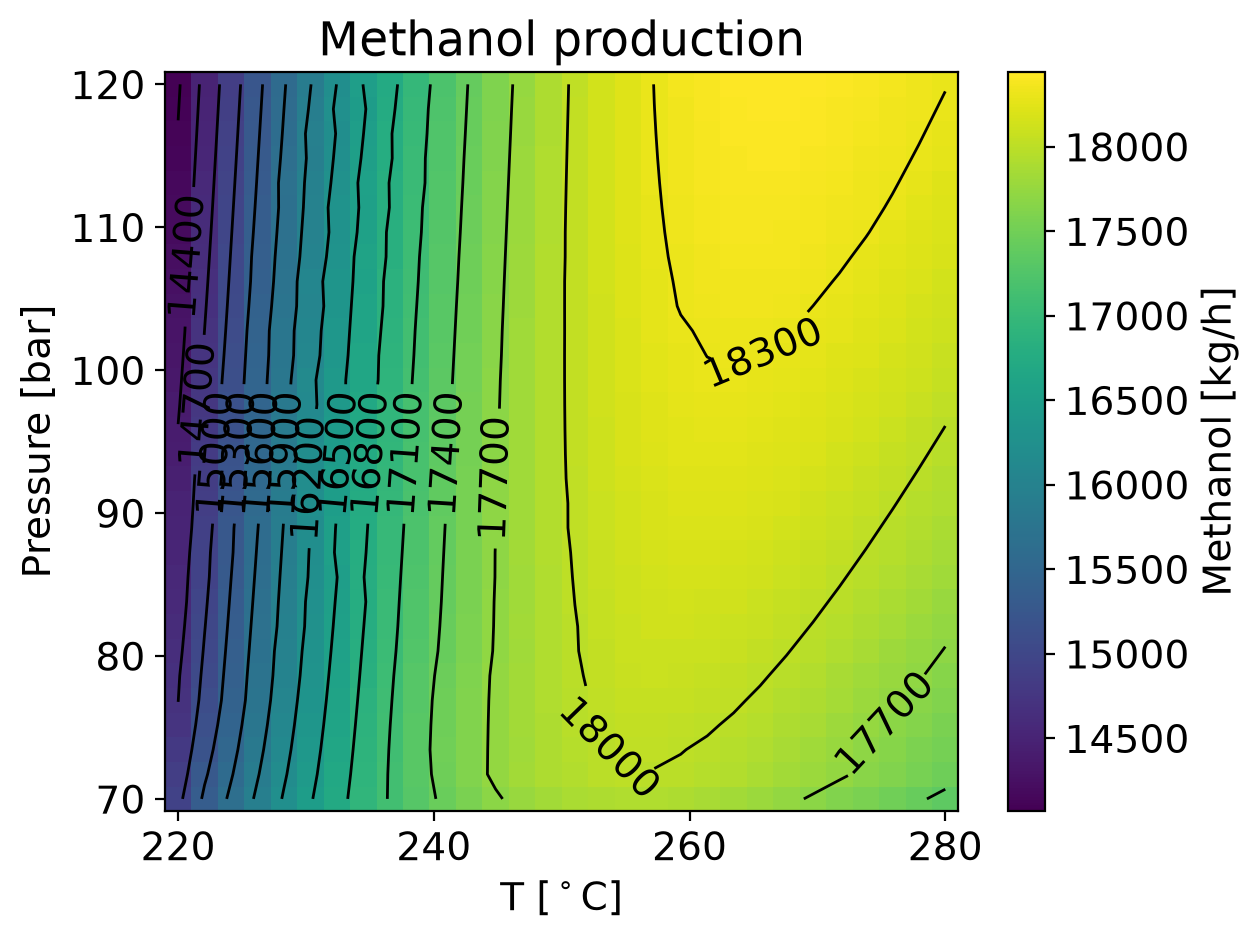

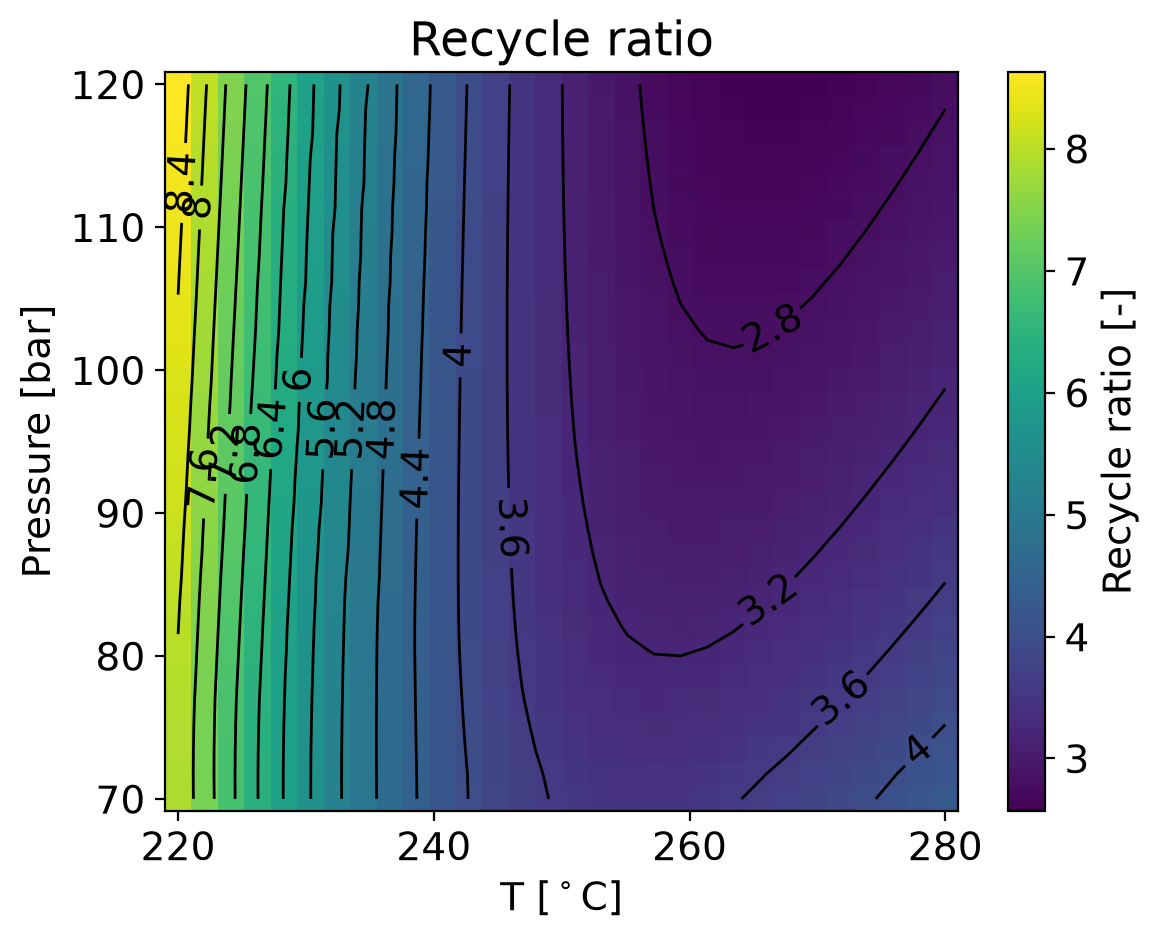

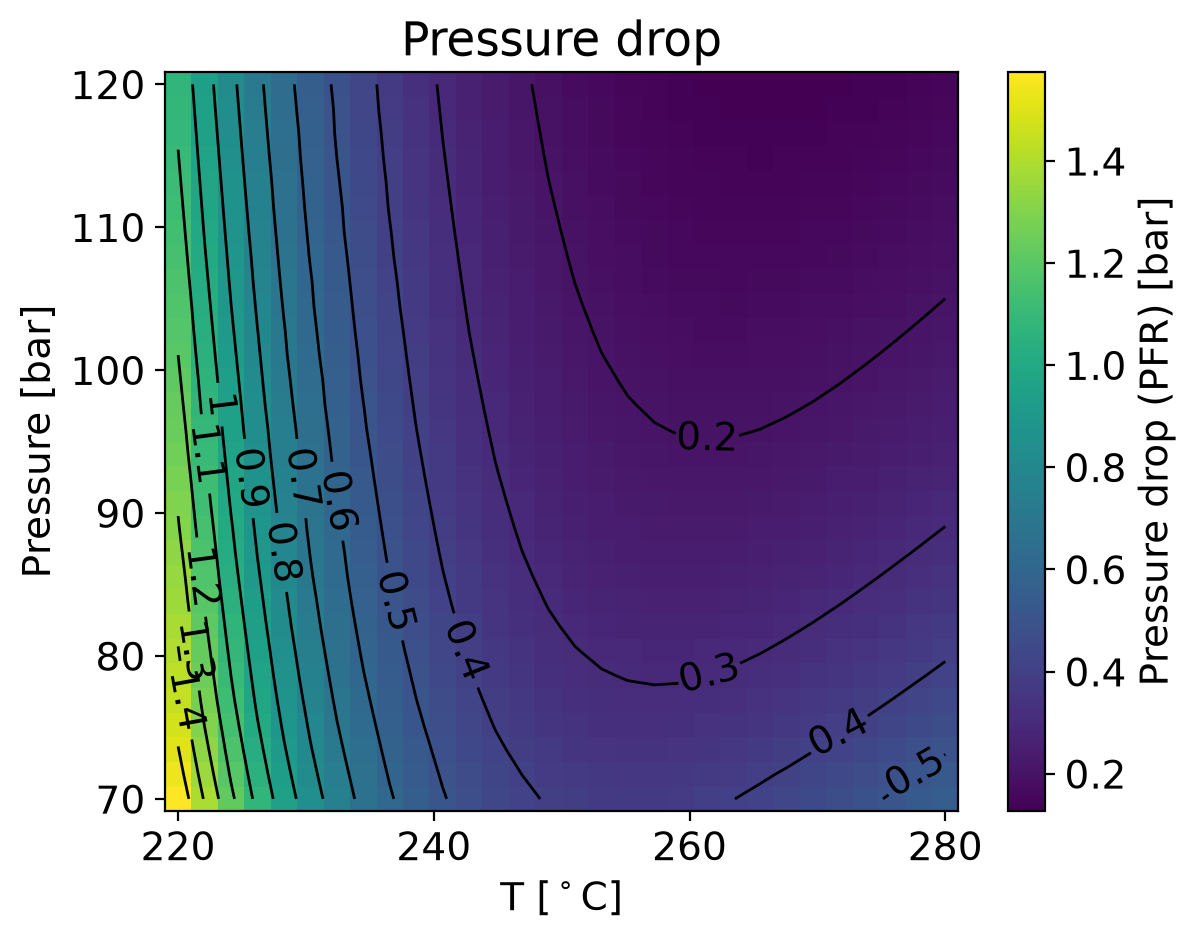

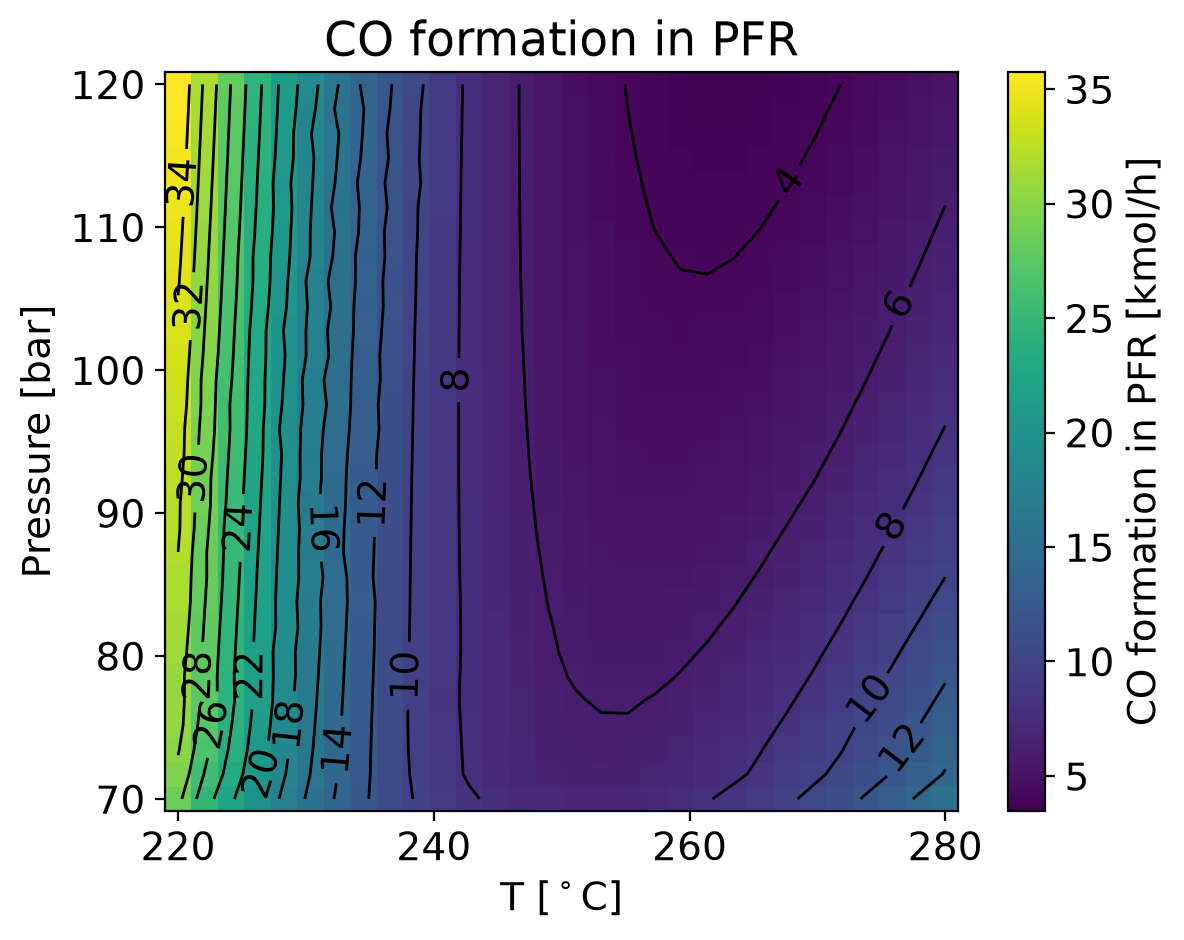

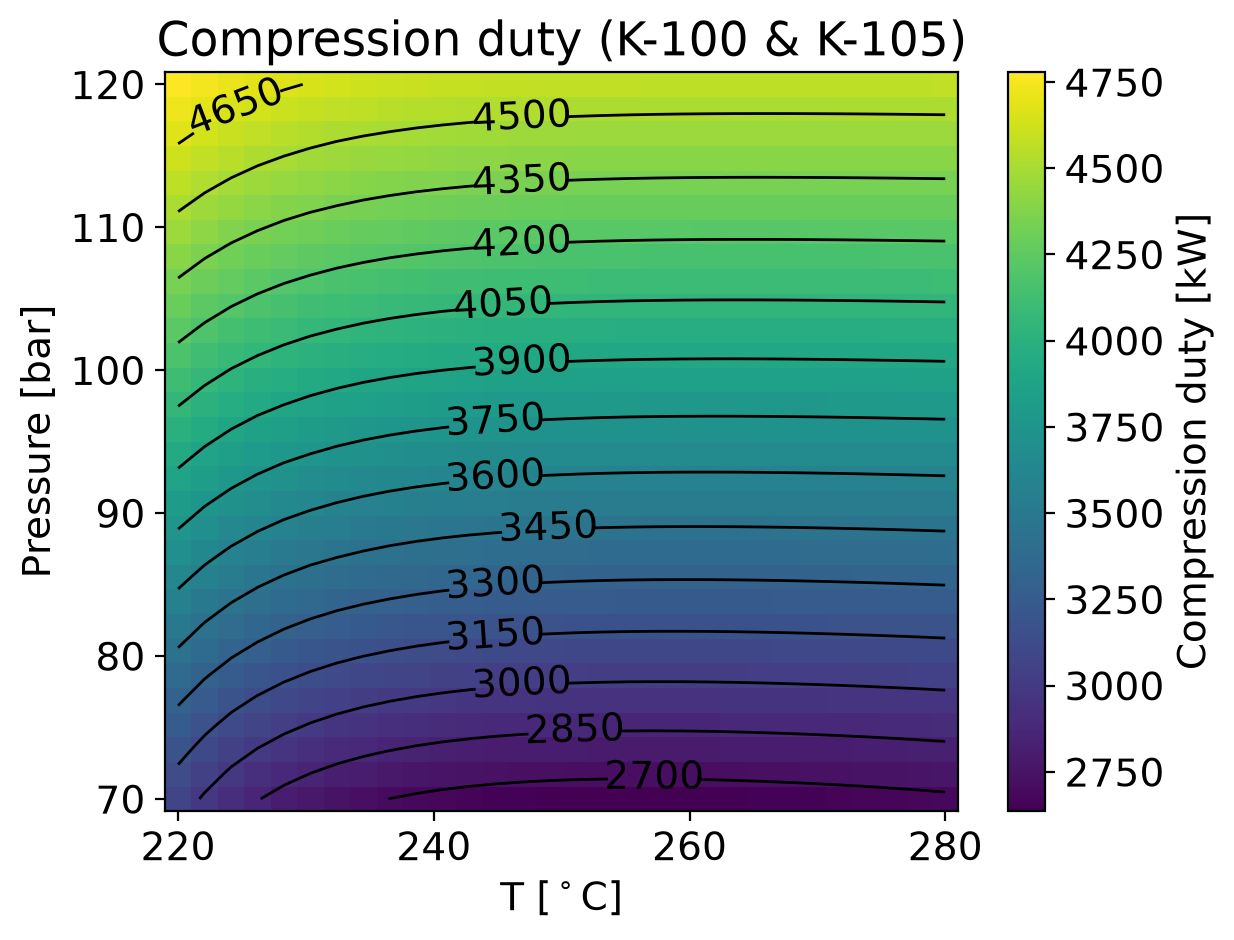

In [7]:
if not SKIP_SENSITIVITY:
    heatmap(df_sweep, "methanol_kg_h", "Methanol [kg/h]", title="Methanol production", levels=15, name="methanol")
    heatmap(df_sweep, "recycle_ratio", "Recycle ratio [-]", title="Recycle ratio", name="recycle_ratio")
    heatmap(df_sweep, "reactor_dP_bar", "Pressure drop (PFR) [bar]", title="Pressure drop", name="reactor_dP")
    heatmap(df_sweep, "co_formation_kgmole_h", "CO formation in PFR [kmol/h]", title="CO formation in PFR", name="co_formation")
    heatmap(df_sweep, "compression_kW", "Compression duty [kW]", title="Compression duty (K-100 & K-105)", name="compression");

## Part B: reactor-inlet domain, the surrogate's training box

In [8]:
# Sobol sample of the loop over the design box; run_point records the reactor inlet at each point
bounds = np.array(list(zip(*design_bounds.values())))          # 2 x d: lower row, upper row
t0 = time.time()
df_hull = loop_rows(generate_sobol_points(N_HULL, bounds), row_hysys)
t_hull = time.time() - t0                                       # s; per-solve cost of the loop for the benchmark
print(f"{len(df_hull)} points, {int(df_hull.converged.sum())} converged, {t_hull:.0f} s")

3/32 0.1 min elapsed
6/32 0.3 min elapsed
9/32 0.4 min elapsed
12/32 0.5 min elapsed
15/32 0.6 min elapsed
18/32 0.6 min elapsed
21/32 0.7 min elapsed
24/32 0.8 min elapsed
27/32 0.9 min elapsed
30/32 1.0 min elapsed
32/32 1.0 min elapsed
32 points, 32 converged, 60 s


In [9]:
# Hull of the reactor inlet over the converged points, inflated -> training box in sur.INPUTS order
# NOTE: Units (Flows): kgmole/s
hull_ok = df_hull[df_hull["converged"]].reset_index(drop=True)
hull = {c: (hull_ok[f"in_{c}_kgmole_h"].min() / 3600, hull_ok[f"in_{c}_kgmole_h"].max() / 3600)   # kgmole/s
        for c in sur.COMPONENTS}
pfr_box = {**design_bounds, **{c: [max(lo - (hi - lo) * INFLATE, 0.0), hi + (hi - lo) * INFLATE] for c, (lo, hi) in hull.items()}}
assert list(pfr_box) == sur.INPUTS
pd.DataFrame(pfr_box, index=["lower", "upper"]).T

,lower,upper
temperature_C,220.000000,280.000000
pressure_bar,70.000000,120.000000
Hydrogen,1.945405,4.980128
CO,0.022183,0.270480
CO2,0.362151,1.215786
H2O,0.007781,0.010088
Methanol,0.002918,0.012520
Nitrogen,0.056926,0.058931


## Part C: PFR sampling and surrogate training

In [10]:
# Reactor sampling: vector in pfr_box order -> one HYSYS solve of the isolated PFR
def pfr_row(x):
    p = dict(zip(pfr_box, x))
    return pfr.run_point(objects_pfr, temperature=(p["temperature_C"], "C"), pressure=(p["pressure_bar"], "bar"),
                         volume=(VOLUME, "m3"), flows=({c: p[c] for c in sur.COMPONENTS}, "kgmole/s"))

def unit_sobol_sample(bounds, model, n_pts):
    lb = np.array([b[0] for b in bounds.values()])
    ub = np.array([b[1] for b in bounds.values()])
    input_var = generate_sobol_points(n=n_pts, bounds=np.stack((lb, ub)))
    results = []
    for iv in input_var:
        res = {**dict(zip(bounds, iv)), **model(iv)}
        results.append(res)
    return pd.DataFrame(results)

t0 = time.time()
df_pfr = unit_sobol_sample(pfr_box, pfr_row, N_PFR)
t_pfr = time.time() - t0                                       # s; per-solve cost of the PFR for the benchmark
print(f"{len(df_pfr)} evaluations, {int(df_pfr.converged.sum())} converged, {t_pfr:.0f} s")
df_pfr.to_csv(f"pfr_sobol{TAG}.csv", index=False)

1024 evaluations, 1024 converged, 56 s


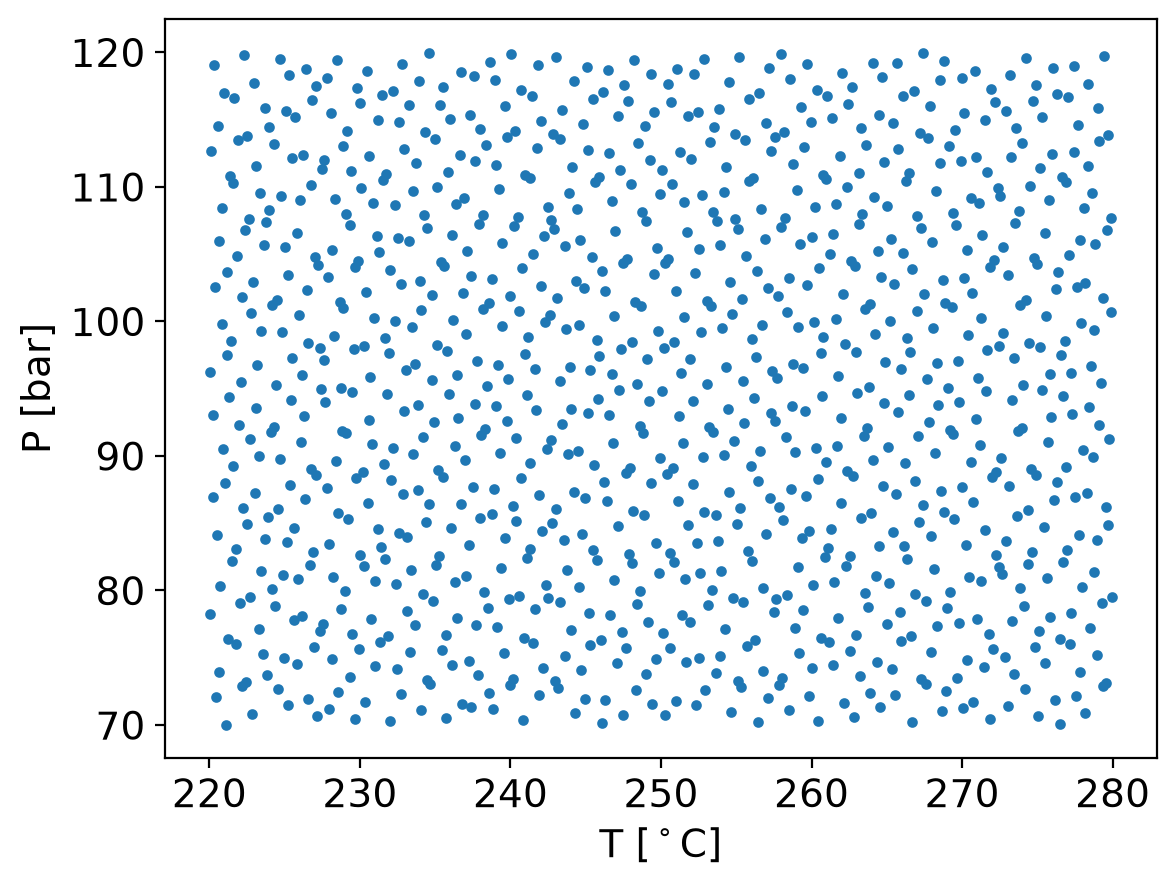

In [11]:
# Sampled design points in the T-P plane; the six flow dimensions are projected out
fig, ax = plt.subplots()
ax.scatter(df_pfr.temperature_C, df_pfr.pressure_bar, s=8)
ax.set(xlabel=r"T [$^\circ$C]", ylabel="P [bar]");


In [12]:
# Two surrogates of the same reactor, trained on the same inputs:
#   stoi: predicts the extents of the two independent reactions
#           xi1: CO2 + 3 H2 -> CH3OH + H2O      xi2: CO2 + H2 -> CO + H2O
#         plus duty and pressure drop; outlet = inlet + sur.STOICH @ extents, so the
#         atom balances hold by construction (sur.stoi_as_raw does that reconstruction).
#   raw:  predicts the six outlet flows plus duty and pressure drop directly.
# NOTE: key "Hydrogen" yields kgmole/s (analogous for other 5 components)
pfr_ok = df_pfr[df_pfr["converged"]].reset_index(drop=True)
X = pfr_ok[list(pfr_box)].to_numpy()                      # inputs in box order
Y_stoi = pd.DataFrame({
    "xi_meoh_kgmole_h": pfr_ok.out_Methanol_kgmole_h - pfr_ok.in_Methanol_kgmole_h,
    "xi_co_kgmole_h":   pfr_ok.out_CO_kgmole_h - pfr_ok.in_CO_kgmole_h,
    "reactor_duty_kW":  pfr_ok.reactor_duty_kW,
    "reactor_dP_bar":   pfr_ok.reactor_dP_bar,
})
Y_raw = pd.concat([pfr_ok[[f"out_{c}_kgmole_h" for c in sur.COMPONENTS]],
                   pfr_ok[["reactor_duty_kW", "reactor_dP_bar"]]], axis=1)
print(f"{len(X)} training points, {X.shape[1]} inputs -> stoi {Y_stoi.shape[1]} outputs, raw {Y_raw.shape[1]} outputs")

1024 training points, 8 inputs -> stoi 4 outputs, raw 8 outputs


In [ ]:
t_train = {} # s, wall time of training per net
t0 = time.time()
stoi, rmse_stoi, oof_stoi = train_surrogate(X, Y_stoi, names=Y_stoi.columns, path=f"pfr_surrogate_stoi{TAG}_2d.txt")
t_train["stoi"] = time.time() - t0
t0 = time.time()
raw, rmse_raw, oof_raw = train_surrogate(X, Y_raw, names=Y_raw.columns, path=f"pfr_surrogate_raw{TAG}_2d.txt")
t_train["raw"] = time.time() - t0
nets = {"stoi": sur.stoi_as_raw(stoi), "raw": raw}       # both with the raw interface: outlet flows, duty, dP

width 64 (48 s)   CV rmse/std per width: 4: 0.0893, 8: 0.0435, 16: 0.0153, 32: 0.0101, 64: 0.0094, 128: 0.0120
  xi_meoh_kgmole_h           2.777    0.21 % of range
  xi_co_kgmole_h             2.445    0.22 % of range
  reactor_duty_kW           62.522    0.20 % of range
  reactor_dP_bar             0.002    0.13 % of range
width 64 (50 s)   CV rmse/std per width: 4: 0.3843, 8: 0.0907, 16: 0.0319, 32: 0.0174, 64: 0.0102, 128: 0.0103
  out_Hydrogen_kgmole_h     19.787    0.17 % of range
  out_CO_kgmole_h            2.272    0.29 % of range
  out_CO2_kgmole_h           6.116    0.18 % of range
  out_H2O_kgmole_h           2.860    0.23 % of range
  out_Methanol_kgmole_h      2.991    0.22 % of range
  out_Nitrogen_kgmole_h      0.015    0.21 % of range
  reactor_duty_kW           66.366    0.21 % of range
  reactor_dP_bar             0.002    0.18 % of range


out-of-fold RMSE of outlet flows [kgmole/h]:
             range  stoi_rmse  raw_rmse
Hydrogen  11856.07       7.99     19.79
CO          772.08       2.45      2.27
CO2        3331.64       3.13      6.12
H2O        1267.25       3.13      2.86
Methanol   1373.08       2.78      2.99
Nitrogen      7.21       0.00      0.01

raw net atom balance error, out minus in [kgmole/h]  (stoi: zero by construction):
  C: rms    5.48   max   25.29
  O: rms   10.65   max   56.90
  H: rms   38.58   max  190.98


WindowsPath('C:/Users/kr326/Documents/MScThesis/figures/Cases/HYSYS_MeOH/parity_pfr_outlets.png')

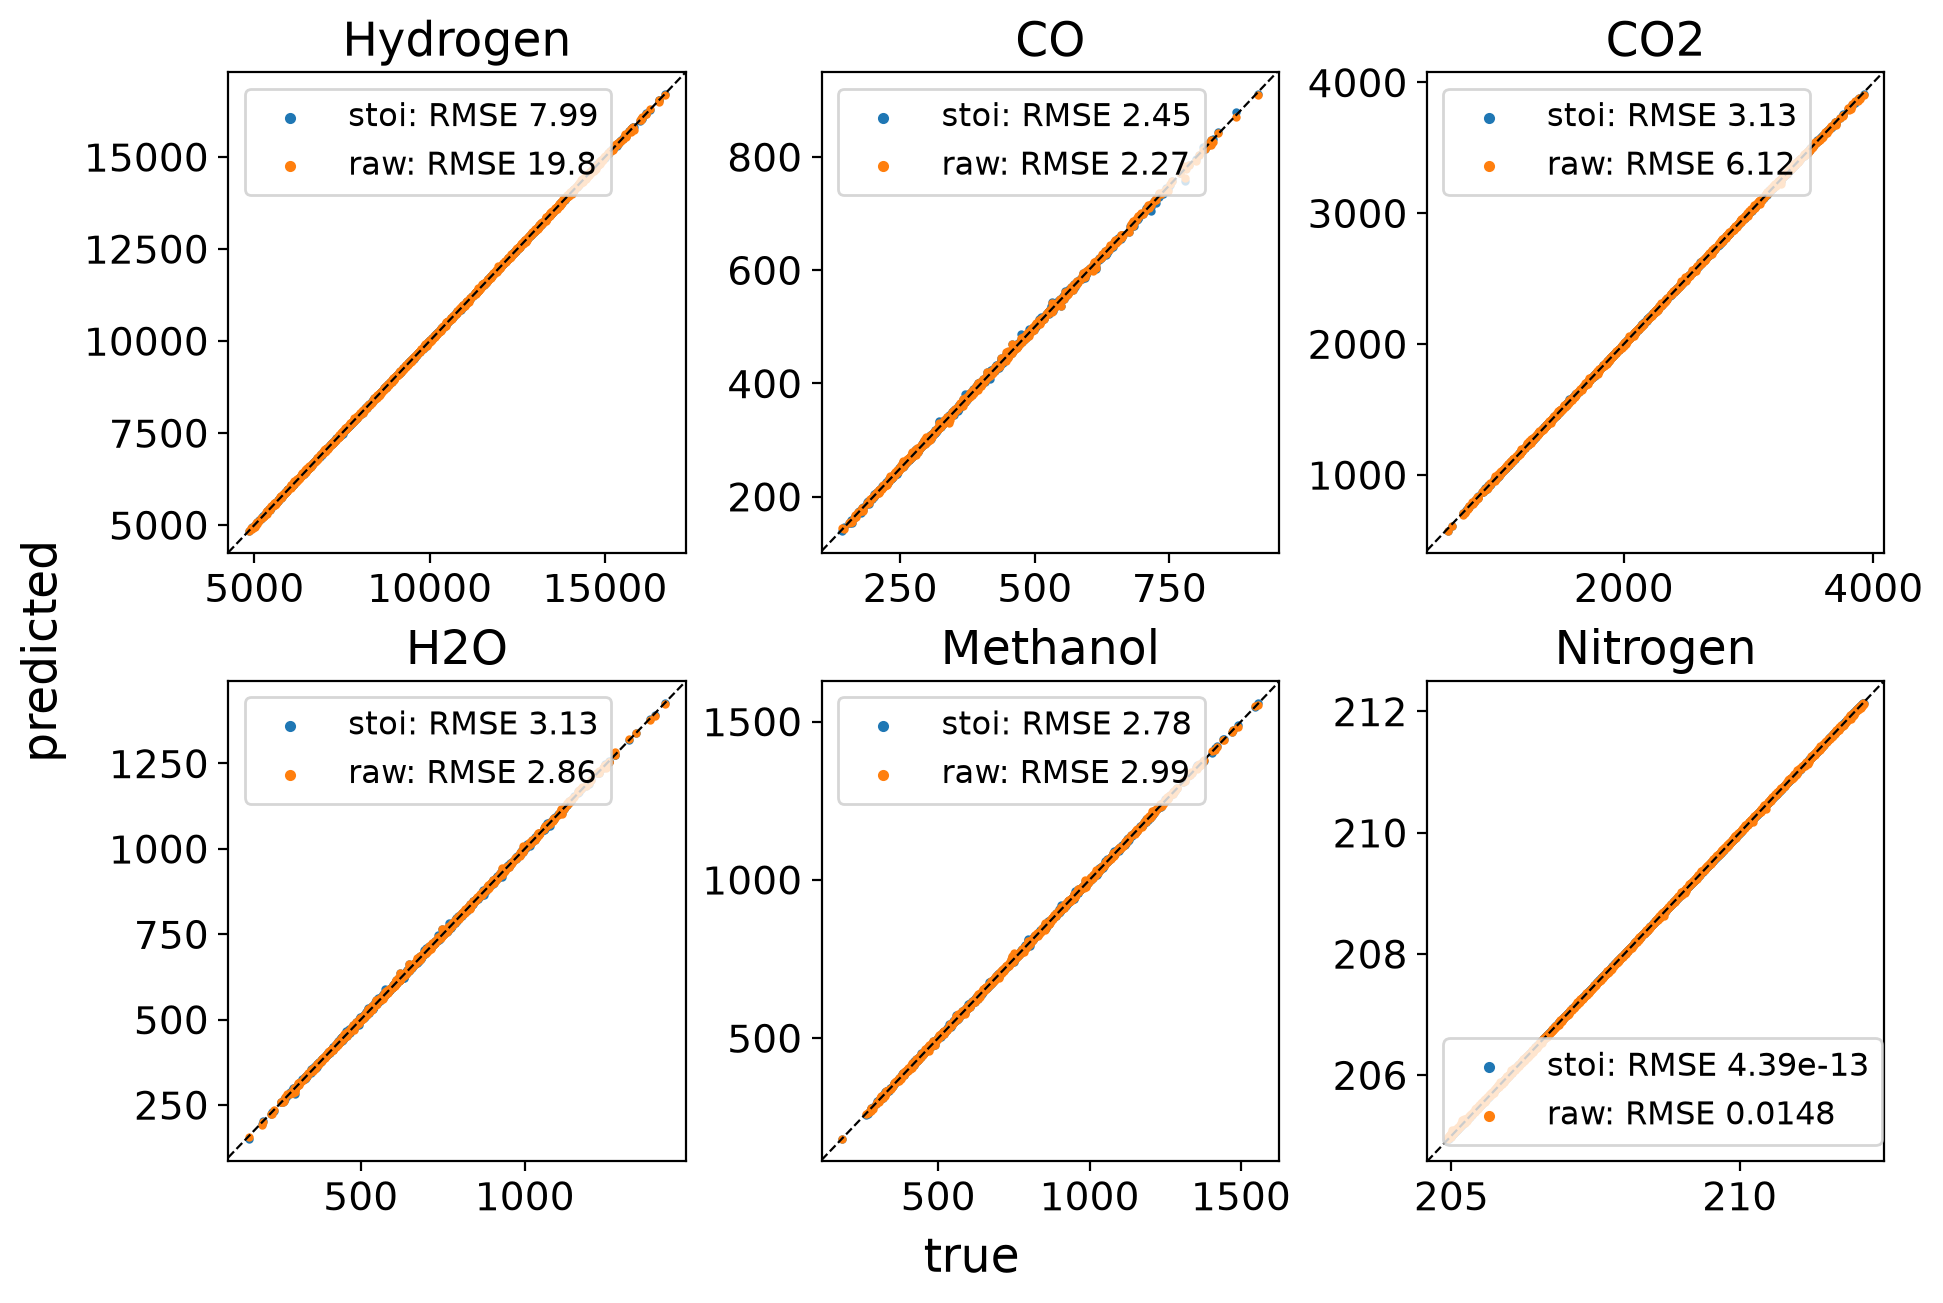

In [14]:
# Side by side on the same footing: outlet flows, with the stoi outlets rebuilt from its
# out-of-fold extents, and the atom balances of the raw net's outlets
inlet = pfr_ok[[f"in_{c}_kgmole_h" for c in sur.COMPONENTS]].to_numpy()
outlet = pfr_ok[[f"out_{c}_kgmole_h" for c in sur.COMPONENTS]].to_numpy()
out_stoi = inlet + oof_stoi[:, :2] @ sur.STOICH.T
comparison = pd.DataFrame({
    "range": outlet.max(0) - outlet.min(0),
    "stoi_rmse": np.sqrt(((out_stoi - outlet) ** 2).mean(0)),
    "raw_rmse": np.sqrt(((oof_raw[:, :6] - outlet) ** 2).mean(0)),
}, index=sur.COMPONENTS).round(2)
print("out-of-fold RMSE of outlet flows [kgmole/h]:")
print(comparison)

ATOMS = {"C": [0, 1, 1, 0, 1, 0], "O": [0, 1, 2, 1, 1, 0], "H": [2, 0, 0, 2, 4, 0]}   # per sur.COMPONENTS
print()
print("raw net atom balance error, out minus in [kgmole/h]  (stoi: zero by construction):")
for atom, v in ATOMS.items():
    err = (oof_raw[:, :6] - inlet) @ np.array(v, float)
    print(f"  {atom}: rms {np.sqrt((err ** 2).mean()):7.2f}   max {np.abs(err).max():7.2f}")
fig, _ = parity_plot(outlet, {"stoi": out_stoi, "raw": oof_raw[:, :6]}, names=sur.COMPONENTS)
save(fig, "Cases/HYSYS_MeOH/parity_pfr_outlets")

In [15]:
# Sanity check on one point: both surrogates against HYSYS
row = pfr_ok.iloc[0]
x = row[list(pfr_box)].to_numpy(dtype=float)
pred = {name: net(x)[:6] for name, net in nets.items()}
for i, c in enumerate(sur.COMPONENTS):
    print(f"  {c:9s} HYSYS {row[f'out_{c}_kgmole_h']:9.2f}   stoi {pred['stoi'][i]:9.2f}   raw {pred['raw'][i]:9.2f} kgmole/h")

  Hydrogen  HYSYS  13759.64   stoi  13755.27   raw  13758.42 kgmole/h
  CO        HYSYS    282.41   stoi    282.12   raw    279.98 kgmole/h
  CO2       HYSYS   1431.54   stoi   1430.27   raw   1436.32 kgmole/h
  H2O       HYSYS    822.79   stoi    824.05   raw    820.42 kgmole/h
  Methanol  HYSYS    667.66   stoi    669.22   raw    668.63 kgmole/h
  Nitrogen  HYSYS    209.29   stoi    209.29   raw    209.30 kgmole/h


## Part D: the loop with the surrogate in place of the PFR

In [16]:
# The cut flowsheet: RoutV is written from the net each tear pass, the rest is solved by HYSYS
objects_sur = sur.cache_objects(case_sur, pfr_box)

def row_surrogate(x, net):
    T, P = x
    return sur.run_point(objects_sur, net, pressure=(P, "bar"), temperature=(T, "C"),
                         ratio=RATIO, purge_rate=PURGE_RATE)

In [17]:
# Point-wise validation against the HYSYS rows of Part B, both nets
KEYS = ["methanol_kg_h", "compression_kW", "co_formation_kgmole_h", "recycle_ratio"]
for name, net in nets.items():
    t0 = time.time()
    pred = loop_rows(hull_ok[list(design_bounds)].to_numpy(), partial(row_surrogate, net=net))
    conv = pred["converged"].to_numpy()
    print(f"=== {name}: {int(conv.sum())}/{len(pred)} converged, mean {pred.tear_passes.mean():.0f} tear passes, "
          f"{int(pred.outside_box.dropna().map(len).gt(0).sum())} points outside the box, {time.time() - t0:.0f} s")
    for k in KEYS:
        err = (pred[k] - hull_ok[k])[conv]
        rmse = np.sqrt((err ** 2).mean())
        print(f"  {k:22s} rmse {rmse:9.3f}   max |err| {err.abs().max():9.3f}   "
              f"({100 * rmse / hull_ok[k].abs().mean():.2f} % of mean)")

3/32 0.0 min elapsed
6/32 0.1 min elapsed
9/32 0.1 min elapsed
12/32 0.1 min elapsed
15/32 0.2 min elapsed
18/32 0.2 min elapsed
21/32 0.2 min elapsed
24/32 0.2 min elapsed
27/32 0.3 min elapsed
30/32 0.3 min elapsed
32/32 0.3 min elapsed
=== stoi: 32/32 converged, mean 18 tear passes, 10 points outside the box, 20 s
  methanol_kg_h          rmse    55.214   max |err|   188.689   (0.32 % of mean)
  compression_kW         rmse     2.134   max |err|     8.039   (0.06 % of mean)
  co_formation_kgmole_h  rmse     0.442   max |err|     2.031   (4.28 % of mean)
  recycle_ratio          rmse     0.030   max |err|     0.081   (0.73 % of mean)
3/32 0.0 min elapsed
6/32 0.1 min elapsed
9/32 0.1 min elapsed
12/32 0.1 min elapsed
15/32 0.1 min elapsed
18/32 0.2 min elapsed
21/32 0.2 min elapsed
24/32 0.2 min elapsed
27/32 0.3 min elapsed
30/32 0.3 min elapsed
32/32 0.3 min elapsed
=== raw: 32/32 converged, mean 18 tear passes, 4 points outside the box, 19 s
  methanol_kg_h          rmse   140.714 

## Part E: feasibility analysis, surrogate loop against the HYSYS benchmark

In [18]:
def nested_sample_flowsheet(box, model, constraints, *, n_live, n_prop, max_time=0):
    """Nested-sample the region where constraints(model(x)) <= 0 over `box`
    ({name: [lb, ub]}, order defines x).  Returns the sampler Result and a
    DataFrame with one row per evaluation, failed ones included."""
    rows = []

    def g(x):
        row = {**dict(zip(box, x)), **model(x)}
        rows.append(row)                          # kept even if the constraints raise
        residuals = constraints(row)
        row["max_residual"] = max(residuals)      # <= 0 means feasible
        return residuals

    lb, ub = zip(*box.values())
    result = NestedSampler(g, lb, ub, num_live=n_live, num_prop=n_prop, max_time=max_time, display_iter=1).sample()
    return result, pd.DataFrame(rows)

In [19]:
# perform nested sampling on both surrogate and original flowsheets
runs = {}
for name, model in (("surrogate", partial(row_surrogate, net=nets[NET])), ("hysys", row_hysys)):
    t0 = time.time()
    result, df = nested_sample_flowsheet(design_bounds, model, partial(constraints, relax = RELAX if name=="surrogate" else 0),
                                         n_live=N_LIVE_SUR if name == "surrogate" else N_LIVE, n_prop=N_PROP, max_time=MAX_TIME)
    df["feasible"] = df["max_residual"] <= 0
    runs[name] = dict(result=result, df=df, wall_s=time.time() - t0)
    print(f"=== {name}: {len(df)} evaluations, {int(df.feasible.sum())} feasible, "
          f"{result.stats.failures} failed, status {result.status.name}, {runs[name]['wall_s']:.0f} s")


** INITIALIZING LIVE POINTS (2048)   1179.88 SEC

Iterate        Contour #Feas    #Dead         Factor
----------------------------------------------------
      0     4.2503e+03   419        0     3.0000e-01
      1     3.4755e+03   426       32     2.9909e-01
      2     3.1184e+03   433       64     2.9816e-01
      3     2.8452e+03   439       94     2.9729e-01
      4     2.6052e+03   445      125     2.9639e-01
      5     2.3949e+03   451      154     2.9555e-01
      6     2.1977e+03   459      184     2.9469e-01
      7     2.0568e+03   463      212     2.9388e-01
      8     1.8955e+03   474      239     2.9311e-01
      9     1.7693e+03   484      269     2.9225e-01
     10     1.6597e+03   492      299     2.9140e-01
     11     1.5755e+03   495      324     2.9068e-01
     12     1.4917e+03   501      351     2.8992e-01
     13     1.4177e+03   506      377     2.8918e-01
     14     1.3269e+03   509      403     2.8845e-01
     15     1.2521e+03   516      426     2.8780

In [20]:
# Verification: surrogate-feasible points re-evaluated on HYSYS, shuffled, until N_LIVE are confirmed
# (live points are sorted by margin: taking them in order would under-sample the boundary; as in the cascades)
sur_df, hys_df = runs["surrogate"]["df"], runs["hysys"]["df"]
cand = sur_df[sur_df.feasible].sample(frac=1, random_state=42)
checks, n_confirmed, t0 = [], 0, time.time()
for x in cand[list(design_bounds)].to_numpy():
    if n_confirmed >= N_LIVE:
        break
    checks.append(row_hysys(x))
    n_confirmed += checks[-1]["converged"] and max(constraints(checks[-1], relax=0)) <= 0
t_ver = time.time() - t0                                   # s, wall time of verification
cand = cand.iloc[:len(checks)].copy()
cand["hysys_max_residual"] = [max(constraints(c, relax=0)) if c["converged"] else np.nan for c in checks]
cand["verified"] = cand.hysys_max_residual <= 0
print(f"{len(cand)} of {int(sur_df.feasible.sum())} surrogate-feasible points re-run on HYSYS in {t_ver:.0f} s: "
      f"{int(cand.verified.sum())} confirmed, {int((~cand.verified).sum())} rejected")


1581 of 2056 surrogate-feasible points re-run on HYSYS in 2707 s: 1024 confirmed, 557 rejected


WindowsPath('C:/Users/kr326/Documents/MScThesis/figures/Cases/HYSYS_MeOH/feasible_simultaneous.png')

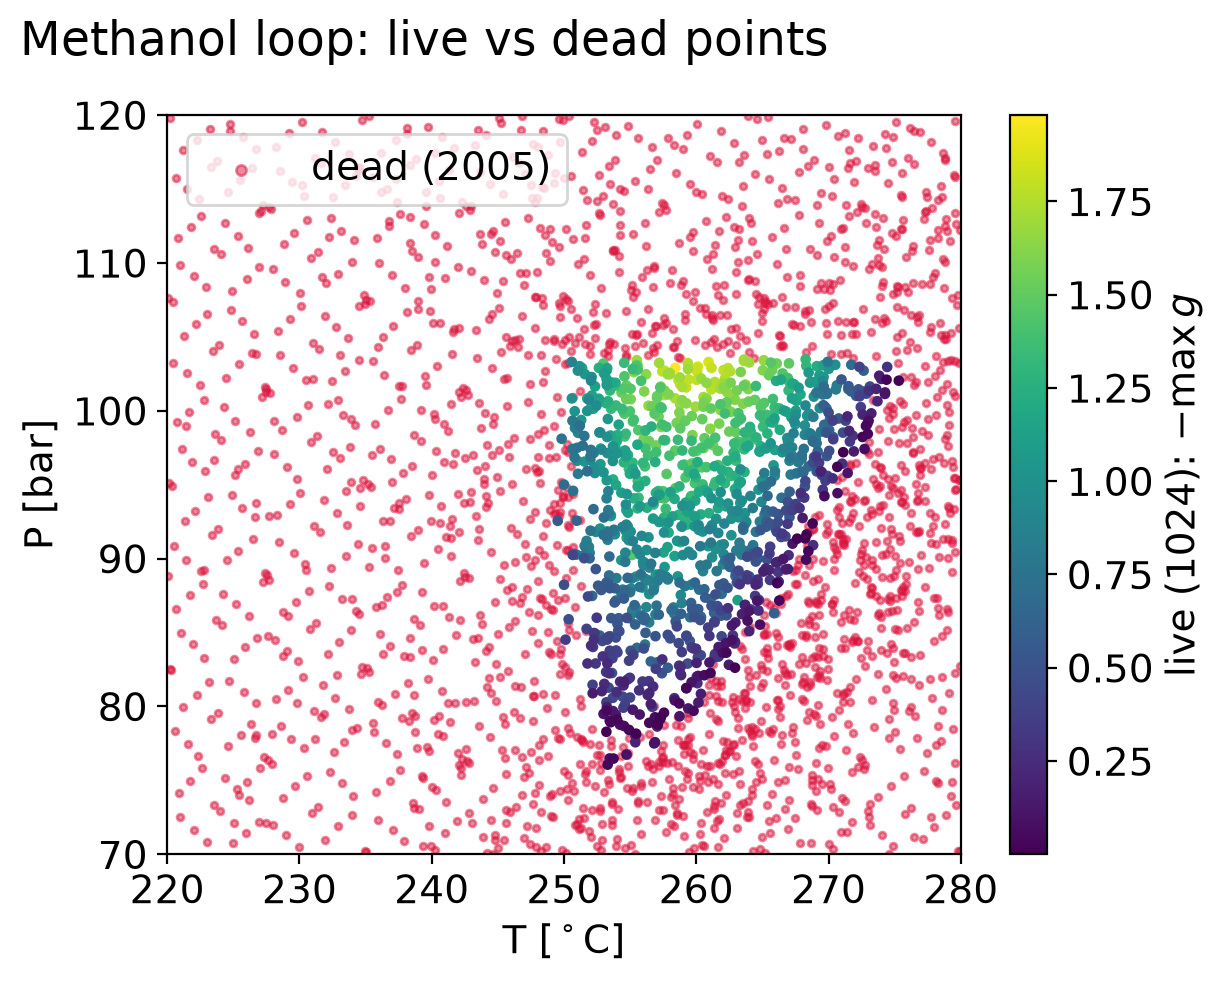

In [21]:
# Live vs dead points of the HYSYS benchmark (2-D: one panel instead of corner and trellis)
hys_live, hys_dead = runs["hysys"]["result"].live, runs["hysys"]["result"].dead      # HYSYS benchmark
fig, ax = plt.subplots()
ax.scatter(hys_dead.x[:, 0], hys_dead.x[:, 1], s=6, alpha=0.5, color="crimson", label=f"dead ({len(hys_dead.x)})")
pcs = ax.scatter(hys_live.x[:, 0], hys_live.x[:, 1], c=-hys_live.value, s=8)
fig.colorbar(pcs, ax=ax, label=f"live ({len(hys_live.x)}): $-\\max g$")
ax.set(xlabel=r"T [$^\circ$C]", ylabel="P [bar]", xlim=design_bounds["temperature_C"], ylim=design_bounds["pressure_bar"])
ax.legend()
fig.suptitle("Methanol loop: live vs dead points", x=0.01, ha="left")
save(fig, "Cases/HYSYS_MeOH/feasible_simultaneous")


WindowsPath('C:/Users/kr326/Documents/MScThesis/figures/Cases/HYSYS_MeOH/feasible_reconstructed.png')

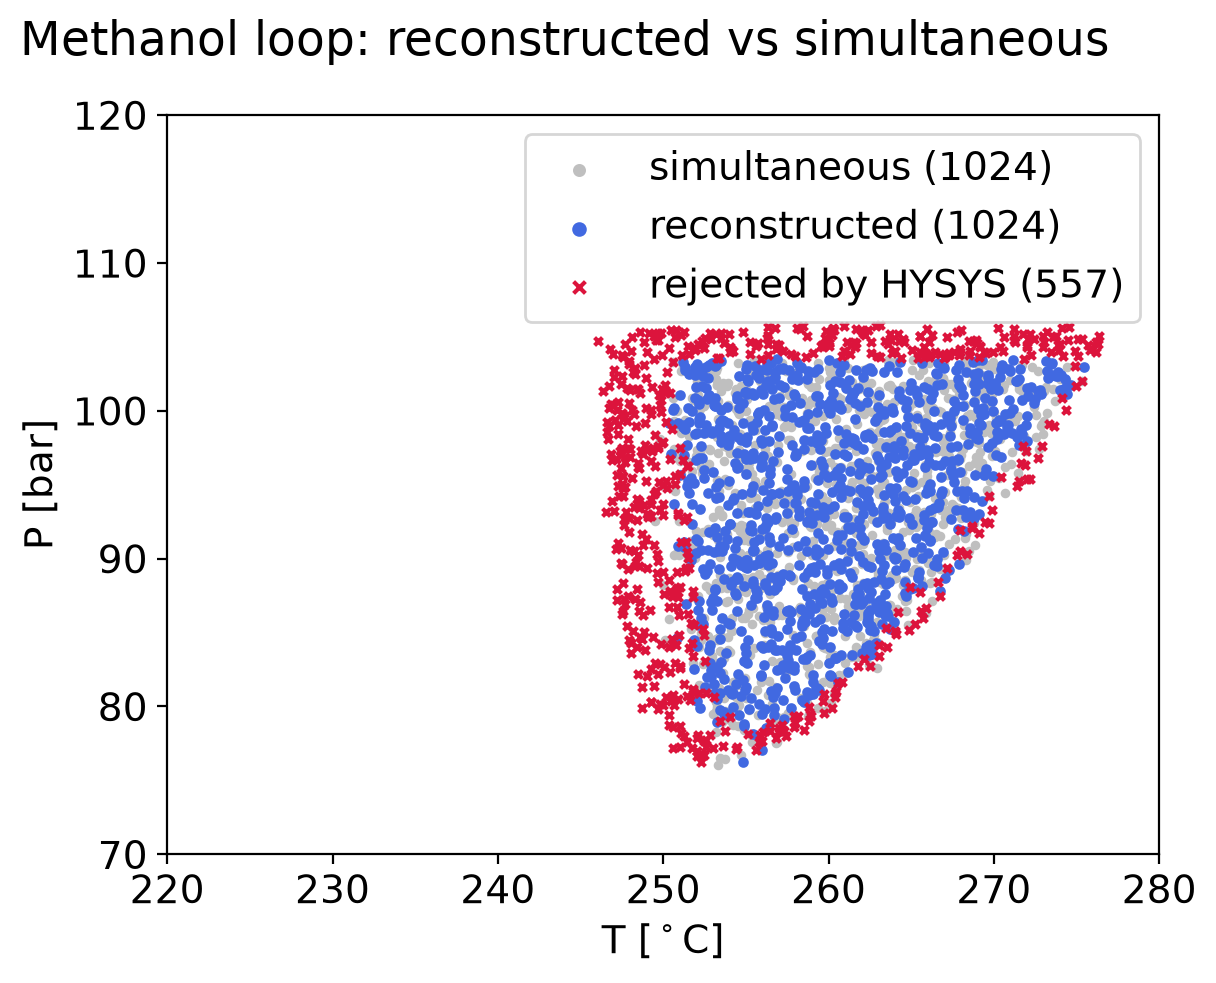

In [22]:
# Reconstructed (verified surrogate candidates) against the simultaneous HYSYS live set
fig, ax = plt.subplots()
hys_feasible = hys_live.x[hys_live.feasible]                        # the simultaneous set: the HYSYS live set, as in 4-D
ax.scatter(hys_feasible[:, 0], hys_feasible[:, 1], s=6, color="0.75", label=f"simultaneous ({len(hys_feasible)})")
ax.scatter(cand.temperature_C[cand.verified], cand.pressure_bar[cand.verified], s=8, color="royalblue",
           label=f"reconstructed ({int(cand.verified.sum())})")
ax.scatter(cand.temperature_C[~cand.verified], cand.pressure_bar[~cand.verified], s=8, marker="x", color="crimson",
           label=f"rejected by HYSYS ({int((~cand.verified).sum())})")
ax.set(xlabel=r"T [$^\circ$C]", ylabel="P [bar]", xlim=design_bounds["temperature_C"], ylim=design_bounds["pressure_bar"])
ax.legend()
fig.suptitle("Methanol loop: reconstructed vs simultaneous", x=0.01, ha="left")
save(fig, "Cases/HYSYS_MeOH/feasible_reconstructed")


In [23]:
KEEP = ["df_sweep", "df_hull", "pfr_box", "df_pfr", "runs", "cand", "t_hull", "t_pfr", "t_train", "t_ver"]
with open(f"backup_2d{TAG}.pkl", "wb") as f:
    pickle.dump({k: globals()[k] for k in KEEP if k in globals()}, f)


In [24]:
def benchmark():
    """Decomposition (Parts B to E, net NET) against nested sampling of the HYSYS loop, in flowsheet
    equivalents as in the cascades (1 EQ = one solve of the HYSYS loop; PFR solves count by solver time;
    surrogate evaluations at no flowsheet cost by convention) and in wall time, where the surrogate loop
    is not free: HYSYS still solves the separation every tear pass."""
    sur_df, hys_df = runs["surrogate"]["df"], runs["hysys"]["df"]
    s_loop = df_hull.solve_time_s.mean()                                   # s per HYSYS loop solve
    eq_hull, eq_pfr, eq_ver = len(df_hull), df_pfr.solve_time_s.sum() / s_loop, len(cand)
    eq_dec, eq_sim = eq_hull + eq_pfr + eq_ver, len(hys_df)
    print(f"decomposition: {eq_dec:.0f} EQ (inlet domain {eq_hull}, PFR sampling {eq_pfr:.0f}, verification {eq_ver}; "
          f"surrogate sampling {len(sur_df)} evaluations at no flowsheet cost)")
    print(f"true feasible rate {100 * cand.verified.mean():.2f} %")
    print(f"simultaneous {eq_sim} EQ")
    print(f"reduction: {100 * (1 - eq_dec / eq_sim):.1f} %")
    print(f"cost ratio: {eq_sim / eq_dec:.1f} (#simultaneous / #decomposed)")
    t_sur, t_sim = runs["surrogate"]["wall_s"], runs["hysys"]["wall_s"]
    t_dec = t_hull + t_pfr + t_train[NET] + t_sur + t_ver
    print(f"wall time: decomposition {t_dec / 60:.1f} min (inlet domain {t_hull / 60:.1f}, PFR sampling {t_pfr / 60:.1f}, "
          f"training {t_train[NET] / 60:.1f}, surrogate sampling {t_sur / 60:.1f}, verification {t_ver / 60:.1f}) "
          f"vs simultaneous {t_sim / 60:.1f} min, speed-up {t_sim / t_dec:.1f}")
    hys_live = runs["hysys"]["result"].live                                     # reconstructed vs simultaneous set, box units
    m = set_metrics(cand.loc[cand.verified, list(design_bounds)].to_numpy(), hys_live.x[hys_live.feasible], bounds)
    print(f"set metrics (box units): Hausdorff {m['hausdorff']:.3f}, Wasserstein {m['wasserstein']:.3f}, "
          f"precision {m['precision']:.2f}, recall {m['recall']:.2f}  (eps {m['eps']:.3f}, {m['n_A']} vs {m['n_B']} points)")

benchmark()


decomposition: 1643 EQ (inlet domain 32, PFR sampling 30, verification 1581; surrogate sampling 8032 evaluations at no flowsheet cost)
true feasible rate 64.77 %
simultaneous 4896 EQ
reduction: 66.4 %
cost ratio: 3.0 (#simultaneous / #decomposed)
wall time: decomposition 148.5 min (inlet domain 1.0, PFR sampling 0.9, training 0.8, surrogate sampling 100.7, verification 45.1) vs simultaneous 145.0 min, speed-up 1.0
set metrics (box units): Hausdorff 0.035, Wasserstein 0.012, precision 0.54, recall 0.54  (eps 0.006, 1024 vs 1024 points)
